In [3]:
# ============================================================
# GENEFORMER EMBEDDING CLASSIFICATION STUDY
#
# Models:
#   1. Logistic Regression
#   2. Deep MLP
#
# Metrics:
#   Accuracy
#   Macro Precision
#   Weighted Precision
#   Macro Recall
#   Weighted Recall
#   Macro F1
#   Weighted F1
#   Macro ROC-AUC
#   Weighted ROC-AUC
#
# DNN:
#   - Train/Validation loss
#   - Train/Validation accuracy
#   - Early stopping on validation Macro-F1
#   - Parameter count
#
# Saved:
#   - Summary results
#   - Per-class metrics
#   - AUC
#   - Confusion matrix
#   - Predictions
#   - Probabilities
#   - Training history
#   - Model architecture
#   - Parameter counts
#   - Plots
# ============================================================


In [65]:
# ============================================================
# 1. IMPORTS
# ============================================================

import os
import copy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)



In [66]:
# ============================================================
# 2. PATHS
# ============================================================
import os
from pathlib import Path

N_Gens = 4096

EMBEDDING_DIR = r"F:\GeneformerProject\data\geneformer_embeddings\first_Strategy"

RESULTS_DIR = Path(r"F:\GeneformerProject\results\first_Strategy") / f"Results_{N_Gens}"
print("OUTPUT_DIR_Path:", RESULTS_DIR)
print("embedding Dir path:",EMBEDDING_DIR)

os.makedirs(RESULTS_DIR, exist_ok=True)

LR_DIR  = os.path.join(RESULTS_DIR, "logistic_regression")
DNN_DIR = os.path.join(RESULTS_DIR, "deep_mlp")

os.makedirs(LR_DIR, exist_ok=True)
os.makedirs(DNN_DIR, exist_ok=True)



OUTPUT_DIR_Path: F:\GeneformerProject\results\first_strategy\preprocessed_14_cancers\Results_4096
embedding Dir path: F:\GeneformerProject\data\geneformer_embeddings\first_strategy\preprocessed_14_cancers


In [67]:
# ============================================================
# 3. RANDOM SEED
# ============================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)


# ============================================================
# 4. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 80)
print("GENEFORMER EMBEDDING CLASSIFIER STUDY")
print("=" * 80)

print("\nDevice:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


GENEFORMER EMBEDDING CLASSIFIER STUDY

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [70]:
# ============================================================
# 5. LOAD EMBEDDINGS
# ============================================================
Train_filename = "train"+ str(N_Gens)+"_embeddings.npy"
print("Train file name:",Train_filename)
X_train = np.load(
    os.path.join(
        EMBEDDING_DIR,
        Train_filename
    )
)
Val_filename = "validation"+ str(N_Gens)+"_embeddings.npy"
X_val = np.load(
    os.path.join(
        EMBEDDING_DIR,
        Val_filename
    )
)

Test_filename = "test"+ str(N_Gens)+"_embeddings.npy"
X_test = np.load(
    os.path.join(
        EMBEDDING_DIR,
        Test_filename
    )
)


# ============================================================
# 6. LOAD LABELS
# ============================================================
Train_filename = "train"+ str(N_Gens)+"_labels.npy"
y_train = np.load(
    os.path.join(
        EMBEDDING_DIR,
        Train_filename
    )
)
Val_filename = "validation"+ str(N_Gens)+"_labels.npy"
y_val = np.load(
    os.path.join(
        EMBEDDING_DIR,
        Val_filename
    )
)
Test_filename = "test"+ str(N_Gens)+"_labels.npy"
y_test = np.load(
    os.path.join(
        EMBEDDING_DIR,
        Test_filename
    )
)


# ============================================================
# 7. BASIC CHECKS
# ============================================================

print("\n" + "=" * 80)
print("DATA")
print("=" * 80)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


INPUT_DIM = X_train.shape[1]

NUM_CLASSES = len(
    np.unique(y_train)
)

print("\nEmbedding dimension:", INPUT_DIM)
print("Number of classes:", NUM_CLASSES)


assert INPUT_DIM == 768, (
    f"Expected 768-dimensional embeddings, "
    f"found {INPUT_DIM}"
)

assert len(np.unique(y_train)) == 33
assert len(np.unique(y_val)) == 33
assert len(np.unique(y_test)) == 33


# ============================================================
# 8. CANCER NAMES
# ============================================================

cancer_names = [
    "acute myeloid leukemia",
    "adrenocortical cancer",
    "bladder urothelial carcinoma",
    "brain lower grade glioma",
    "breast invasive carcinoma",
    "cervical & endocervical cancer",
    "cholangiocarcinoma",
    "colon adenocarcinoma",
    "diffuse large B-cell lymphoma",
    "esophageal carcinoma",
    "glioblastoma multiforme",
    "head & neck squamous cell carcinoma",
    "kidney chromophobe",
    "kidney clear cell carcinoma",
    "kidney papillary cell carcinoma",
    "liver hepatocellular carcinoma",
    "lung adenocarcinoma",
    "lung squamous cell carcinoma",
    "mesothelioma",
    "ovarian serous cystadenocarcinoma",
    "pancreatic adenocarcinoma",
    "pheochromocytoma & paraganglioma",
    "prostate adenocarcinoma",
    "rectum adenocarcinoma",
    "sarcoma",
    "skin cutaneous melanoma",
    "stomach adenocarcinoma",
    "testicular germ cell tumor",
    "thymoma",
    "thyroid carcinoma",
    "uterine carcinosarcoma",
    "uterine corpus endometrioid carcinoma",
    "uveal melanoma"
]

assert len(cancer_names) == NUM_CLASSES

Train file name: train4096_embeddings.npy

DATA
X_train: (4879, 768)
y_train: (4879,)
X_val: (1046, 768)
y_val: (1046,)
X_test: (1046, 768)
y_test: (1046,)

Embedding dimension: 768
Number of classes: 14


In [71]:
# ============================================================
# 9. COMMON EVALUATION FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred,
    y_proba
):

    results = {}

    results["Accuracy"] = accuracy_score(
        y_true,
        y_pred
    )

    results["Macro_Precision"] = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    results["Weighted_Precision"] = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results["Macro_Recall"] = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    results["Weighted_Recall"] = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results["Macro_F1"] = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    results["Weighted_F1"] = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results["Macro_AUC"] = roc_auc_score(
        y_true,
        y_proba,
        multi_class="ovr",
        average="macro"
    )

    results["Weighted_AUC"] = roc_auc_score(
        y_true,
        y_proba,
        multi_class="ovr",
        average="weighted"
    )

    return results


# ============================================================
# 10. STANDARDIZE EMBEDDINGS FOR CLASSIFIERS
# ============================================================

print("\n" + "=" * 80)
print("STANDARDIZATION")
print("=" * 80)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_val_scaled = scaler.transform(
    X_val
)

X_test_scaled = scaler.transform(
    X_test
)

print("Standardization fitted on TRAIN only.")



STANDARDIZATION
Standardization fitted on TRAIN only.


In [72]:
# ============================================================
# ============================================================
#                  MODEL 1 — LOGISTIC REGRESSION
# ============================================================
# ============================================================

print("\n" + "=" * 80)
print("MODEL 1 — LOGISTIC REGRESSION")
print("=" * 80)


# ============================================================
# 11. TRAIN LR
# ============================================================

logreg = LogisticRegression(
    C=1.0,
    max_iter=2000,
    solver="lbfgs",
    random_state=RANDOM_STATE
)

logreg.fit(
    X_train_scaled,
    y_train
)

print("✓ Logistic Regression trained.")


# ============================================================
# 12. LR PREDICTIONS
# ============================================================

lr_train_pred = logreg.predict(
    X_train_scaled
)

lr_val_pred = logreg.predict(
    X_val_scaled
)

lr_test_pred = logreg.predict(
    X_test_scaled
)

lr_train_proba = logreg.predict_proba(
    X_train_scaled
)

lr_val_proba = logreg.predict_proba(
    X_val_scaled
)

lr_test_proba = logreg.predict_proba(
    X_test_scaled
)


# ============================================================
# 13. LR METRICS
# ============================================================

lr_train_metrics = calculate_metrics(
    y_train,
    lr_train_pred,
    lr_train_proba
)

lr_val_metrics = calculate_metrics(
    y_val,
    lr_val_pred,
    lr_val_proba
)

lr_test_metrics = calculate_metrics(
    y_test,
    lr_test_pred,
    lr_test_proba
)


# ============================================================
# 14. PRINT LR RESULTS
# ============================================================

print("\nLR TRAIN")

for key, value in lr_train_metrics.items():
    print(
        f"{key:22s}: {value:.6f}"
    )


print("\nLR VALIDATION")

for key, value in lr_val_metrics.items():
    print(
        f"{key:22s}: {value:.6f}"
    )


print("\nLR TEST")

for key, value in lr_test_metrics.items():
    print(
        f"{key:22s}: {value:.6f}"
    )


# ============================================================
# 15. LR SUMMARY TABLE
# ============================================================

lr_summary = pd.DataFrame([

    {
        "Model": "Logistic Regression",
        "Dataset": "Train",
        **lr_train_metrics
    },

    {
        "Model": "Logistic Regression",
        "Dataset": "Validation",
        **lr_val_metrics
    },

    {
        "Model": "Logistic Regression",
        "Dataset": "Test",
        **lr_test_metrics
    }

])


lr_summary.to_csv(
    os.path.join(
        LR_DIR,
        "logistic_regression_results.csv"
    ),
    index=False
)


# ============================================================
# 16. LR PER-CLASS REPORT
# ============================================================

lr_report = classification_report(
    y_test,
    lr_test_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=cancer_names,
    output_dict=True,
    zero_division=0
)

lr_report_df = pd.DataFrame(
    lr_report
).transpose()

lr_report_df.to_csv(
    os.path.join(
        LR_DIR,
        "logistic_regression_classification_report.csv"
    )
)


# ============================================================
# 17. LR CONFUSION MATRIX
# ============================================================

lr_cm = confusion_matrix(
    y_test,
    lr_test_pred,
    labels=np.arange(NUM_CLASSES)
)

lr_cm_df = pd.DataFrame(
    lr_cm,
    index=cancer_names,
    columns=cancer_names
)

lr_cm_df.to_csv(
    os.path.join(
        LR_DIR,
        "logistic_regression_confusion_matrix.csv"
    )
)

# ============================================================
# 18. LR TEST PREDICTIONS
# ============================================================

lr_predictions_df = pd.DataFrame({

    "True_Label": y_test,

    "True_Cancer": [
        cancer_names[i]
        for i in y_test
    ],

    "Predicted_Label": lr_test_pred,

    "Predicted_Cancer": [
        cancer_names[i]
        for i in lr_test_pred
    ]

})

lr_predictions_df.to_csv(
    os.path.join(
        LR_DIR,
        "logistic_regression_test_predictions.csv"
    ),
    index=False
)



MODEL 1 — LOGISTIC REGRESSION
✓ Logistic Regression trained.

LR TRAIN
Accuracy              : 1.000000
Macro_Precision       : 1.000000
Weighted_Precision    : 1.000000
Macro_Recall          : 1.000000
Weighted_Recall       : 1.000000
Macro_F1              : 1.000000
Weighted_F1           : 1.000000
Macro_AUC             : 1.000000
Weighted_AUC          : 1.000000

LR VALIDATION
Accuracy              : 0.962715
Macro_Precision       : 0.963489
Weighted_Precision    : 0.962923
Macro_Recall          : 0.962804
Weighted_Recall       : 0.962715
Macro_F1              : 0.963017
Weighted_F1           : 0.962680
Macro_AUC             : 0.999089
Weighted_AUC          : 0.998992

LR TEST
Accuracy              : 0.956023
Macro_Precision       : 0.955128
Weighted_Precision    : 0.956623
Macro_Recall          : 0.957844
Weighted_Recall       : 0.956023
Macro_F1              : 0.956319
Weighted_F1           : 0.956185
Macro_AUC             : 0.998551
Weighted_AUC          : 0.998409


F:\GeneformerProject\geneformer_env\Lib\site-packages\sklearn\metrics\_classification.py:3106: UserWarning: labels size, 14, does not match size of target_names, 33
  warnings.warn(


ValueError: Shape of passed values is (14, 14), indices imply (33, 33)

In [55]:
# ============================================================
# ============================================================
#                     MODEL 2 — DEEP MLP
# ============================================================
# ============================================================

print("\n" + "=" * 80)
print("MODEL 2 — DEEP MLP")
print("=" * 80)


# ============================================================
# 19. DNN SETTINGS
# ============================================================

BATCH_SIZE = 64

LEARNING_RATE = 7e-5 #1e-4

WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 500

DROPOUT = 0.50

PATIENCE = 30


# ============================================================
# 20. PYTORCH TENSORS
# ============================================================

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)



MODEL 2 — DEEP MLP


In [57]:
# ============================================================
# 21. DATALOADER
# ============================================================
print("Make Data ready for DNN")
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)



Make Data ready for DNN


In [58]:
# ============================================================
# 22. DNN ARCHITECTURE
# ============================================================

class DeepMLP(nn.Module):

    def __init__(
        self,
        input_dim=768,
        num_classes=33,
        dropout=0.30
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                512
            ),

            nn.BatchNorm1d(512),

            nn.ReLU(),

            nn.Dropout(dropout),


            #nn.Linear(
             #   1024,
             #   512
            #),

            #nn.BatchNorm1d(512),

            #nn.ReLU(),

            #nn.Dropout(dropout),



            
            nn.Linear(
                512,
                256
            ),

            nn.BatchNorm1d(256),

            nn.ReLU(),

            nn.Dropout(dropout),
            


            nn.Linear(
                256,
                128
            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.Dropout(dropout),


            nn.Linear(
                128,
                64
            ),

            nn.BatchNorm1d(64),

            nn.ReLU(),

            nn.Dropout(dropout),

        
            
           
            

            nn.Linear(
                64,
                num_classes
            )
        )


    def forward(self, x):

        return self.network(x)


# ============================================================
# 23. CREATE DNN
# ============================================================

deep_mlp = DeepMLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(device)


print("\nArchitecture:")
print(deep_mlp)



Architecture:
DeepMLP(
  (network): Sequential(
    (0): Linear(in_features=768, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.5, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.5, inplace=False)
    (12): Linear(in_features=128, out_features=64, bias=True)
    (13): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): Dropout(p=0.5, inplace=False)
    (16): Linear(in_features=64, out_features=33, bias=True)
  )
)


In [59]:
# ============================================================
# 24. PARAMETER COUNT
# ============================================================

total_parameters = sum(
    p.numel()
    for p in deep_mlp.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in deep_mlp.parameters()
    if p.requires_grad
)

non_trainable_parameters = (
    total_parameters -
    trainable_parameters
)


print("\n" + "=" * 80)
print("DNN PARAMETERS")
print("=" * 80)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Non-trainable parameters:",
    non_trainable_parameters
)


# ============================================================
# 25. SAVE ARCHITECTURE AND PARAMETERS
# ============================================================

with open(
    os.path.join(
        DNN_DIR,
        "deep_mlp_architecture.txt"
    ),
    "w"
) as f:

    f.write(
        str(deep_mlp)
    )

    f.write(
        "\n\nParameter summary\n"
    )

    f.write(
        f"Input dimension: {INPUT_DIM}\n"
    )

    f.write(
        f"Number of classes: {NUM_CLASSES}\n"
    )

    f.write(
        f"Dropout: {DROPOUT}\n"
    )

    f.write(
        f"Batch size: {BATCH_SIZE}\n"
    )

    f.write(
        f"Learning rate: {LEARNING_RATE}\n"
    )

    f.write(
        f"Weight decay: {WEIGHT_DECAY}\n"
    )

    f.write(
        f"Maximum epochs: {MAX_EPOCHS}\n"
    )

    f.write(
        f"Early stopping patience: {PATIENCE}\n"
    )

    f.write(
        f"Total parameters: {total_parameters}\n"
    )

    f.write(
        f"Trainable parameters: "
        f"{trainable_parameters}\n"
    )


# ============================================================
# 26. LOSS AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    deep_mlp.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)




DNN PARAMETERS
Total parameters: 570273
Trainable parameters: 570273
Non-trainable parameters: 0


In [60]:
# ============================================================
# 27. TRAINING
# ============================================================

best_val_f1 = -np.inf

best_state = None

epochs_without_improvement = 0

history = []


print("\n" + "=" * 80)
print("TRAINING")
print("=" * 80)


for epoch in range(MAX_EPOCHS):


    # ========================================================
    # TRAIN
    # ========================================================

    deep_mlp.train()

    epoch_loss = 0.0

    train_preds = []

    train_true = []


    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)

        y_batch = y_batch.to(device)


        optimizer.zero_grad()


        logits = deep_mlp(
            X_batch
        )


        loss = criterion(
            logits,
            y_batch
        )


        loss.backward()

        optimizer.step()


        epoch_loss += loss.item()


        predictions = torch.argmax(
            logits,
            dim=1
        )


        train_preds.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        train_true.extend(
            y_batch.detach()
            .cpu()
            .numpy()
        )


    train_loss = (
        epoch_loss /
        len(train_loader)
    )


    train_accuracy = accuracy_score(
        train_true,
        train_preds
    )


    train_f1 = f1_score(
        train_true,
        train_preds,
        average="macro"
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    deep_mlp.eval()

    with torch.no_grad():

        val_logits = deep_mlp(
            X_val_tensor.to(device)
        )

        val_loss = criterion(
            val_logits,
            y_val_tensor.to(device)
        ).item()

        val_proba = torch.softmax(
            val_logits,
            dim=1
        ).cpu().numpy()


    val_pred = np.argmax(
        val_proba,
        axis=1
    )


    val_accuracy = accuracy_score(
        y_val,
        val_pred
    )


    val_f1 = f1_score(
        y_val,
        val_pred,
        average="macro"
    )


    val_weighted_f1 = f1_score(
        y_val,
        val_pred,
        average="weighted"
    )


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history.append({

        "Epoch": epoch + 1,

        "Train_Loss": train_loss,

        "Train_Accuracy": train_accuracy,

        "Train_Macro_F1": train_f1,

        "Val_Loss": val_loss,

        "Val_Accuracy": val_accuracy,

        "Val_Macro_F1": val_f1,

        "Val_Weighted_F1": val_weighted_f1

    })


    # ========================================================
    # BEST MODEL
    # ========================================================

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        best_state = copy.deepcopy(
            deep_mlp.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1


    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Epoch {epoch+1:03d} | "
        f"Train Loss={train_loss:.4f} | "
        f"Train Acc={train_accuracy:.4f} | "
        f"Val Loss={val_loss:.4f} | "
        f"Val Acc={val_accuracy:.4f} | "
        f"Val Macro-F1={val_f1:.4f}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping at epoch "
            f"{epoch+1}"
        )

        break


# ============================================================
# 28. RESTORE BEST MODEL
# ============================================================

deep_mlp.load_state_dict(
    best_state
)

deep_mlp.eval()


# ============================================================
# 29. SAVE MODEL
# ============================================================

torch.save(
    deep_mlp.state_dict(),
    os.path.join(
        DNN_DIR,
        "deep_mlp_best_model.pt"
    )
)


# ============================================================
# 30. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history
)

history_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_training_history.csv"
    ),
    index=False
)



TRAINING
Epoch 001 | Train Loss=3.5568 | Train Acc=0.0437 | Val Loss=3.2680 | Val Acc=0.3291 | Val Macro-F1=0.2394
Epoch 002 | Train Loss=3.3162 | Train Acc=0.1067 | Val Loss=3.0413 | Val Acc=0.5455 | Val Macro-F1=0.3463
Epoch 003 | Train Loss=3.1078 | Train Acc=0.1908 | Val Loss=2.8427 | Val Acc=0.5955 | Val Macro-F1=0.3586
Epoch 004 | Train Loss=2.9058 | Train Acc=0.2895 | Val Loss=2.6323 | Val Acc=0.6251 | Val Macro-F1=0.3743
Epoch 005 | Train Loss=2.7350 | Train Acc=0.3579 | Val Loss=2.4166 | Val Acc=0.6546 | Val Macro-F1=0.3876
Epoch 006 | Train Loss=2.5654 | Train Acc=0.4171 | Val Loss=2.2635 | Val Acc=0.6661 | Val Macro-F1=0.3896
Epoch 007 | Train Loss=2.4204 | Train Acc=0.4669 | Val Loss=2.1139 | Val Acc=0.6775 | Val Macro-F1=0.3979
Epoch 008 | Train Loss=2.3001 | Train Acc=0.4954 | Val Loss=1.9707 | Val Acc=0.6727 | Val Macro-F1=0.3860
Epoch 009 | Train Loss=2.1742 | Train Acc=0.5366 | Val Loss=1.8451 | Val Acc=0.6751 | Val Macro-F1=0.3867
Epoch 010 | Train Loss=2.0854 | Trai


DNN FINAL RESULTS

TRAIN
Accuracy              : 0.977138
Macro_Precision       : 0.954008
Weighted_Precision    : 0.965963
Macro_Recall          : 0.931131
Weighted_Recall       : 0.977138
Macro_F1              : 0.927866
Weighted_F1           : 0.968689
Macro_AUC             : 0.999194
Weighted_AUC          : 0.999401

VALIDATION
Accuracy              : 0.931284
Macro_Precision       : 0.873842
Weighted_Precision    : 0.917863
Macro_Recall          : 0.863143
Weighted_Recall       : 0.931284
Macro_F1              : 0.864009
Weighted_F1           : 0.922706
Macro_AUC             : 0.995727
Weighted_AUC          : 0.997084

TEST
Accuracy              : 0.922242
Macro_Precision       : 0.886783
Weighted_Precision    : 0.912090
Macro_Recall          : 0.870233
Weighted_Recall       : 0.922242
Macro_F1              : 0.870281
Weighted_F1           : 0.914721
Macro_AUC             : 0.996797
Weighted_AUC          : 0.997093

DNN PER-CLASS ONE-VS-REST ACCURACY
                          Can

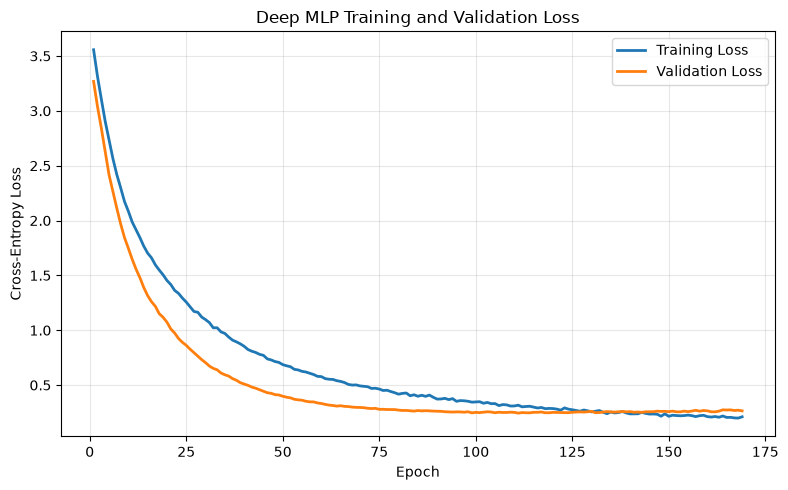

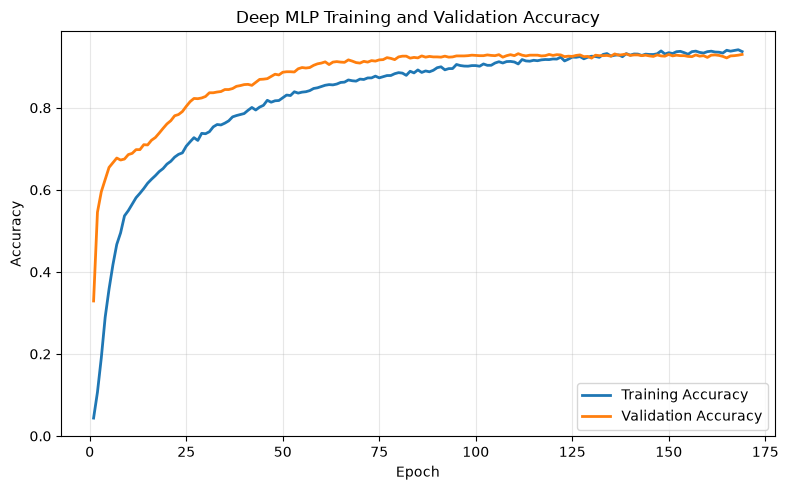

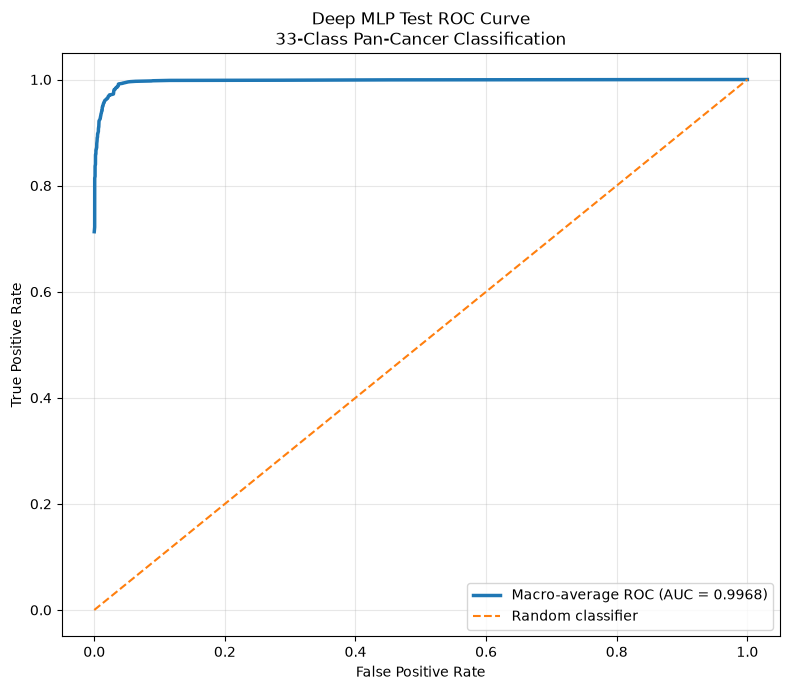


FINAL TEST COMPARISON
              Model  Accuracy  Macro_Precision  Weighted_Precision  Macro_Recall  Weighted_Recall  Macro_F1  Weighted_F1  Macro_AUC  Weighted_AUC
Logistic Regression    0.9198           0.9007              0.9202        0.8906           0.9198    0.8932       0.9187     0.9975        0.9973
           Deep MLP    0.9222           0.8868              0.9121        0.8702           0.9222    0.8703       0.9147     0.9968        0.9971

DNN PARAMETERS
Total parameters: 570273
Trainable parameters: 570273

Best validation Macro-F1:
0.864009

ALL RESULTS SAVED
Main directory: F:\GeneformerProject\results\first_Strategy\Results_4096

Logistic Regression:
F:\GeneformerProject\results\first_Strategy\Results_4096\logistic_regression

Deep MLP:
F:\GeneformerProject\results\first_Strategy\Results_4096\deep_mlp

Finished.


In [62]:
# ============================================================
# ============================================================
#                  DNN FINAL EVALUATION
# ============================================================
# ============================================================


# ============================================================
# 31. PREDICTIONS
# ============================================================

def predict_dnn(
    model,
    X_tensor
):

    model.eval()

    with torch.no_grad():

        logits = model(
            X_tensor.to(device)
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        ).cpu().numpy()

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    return predictions, probabilities


dnn_train_pred, dnn_train_proba = predict_dnn(
    deep_mlp,
    X_train_tensor
)

dnn_val_pred, dnn_val_proba = predict_dnn(
    deep_mlp,
    X_val_tensor
)

dnn_test_pred, dnn_test_proba = predict_dnn(
    deep_mlp,
    X_test_tensor
)


# ============================================================
# 32. FINAL DNN METRICS
# ============================================================

dnn_train_metrics = calculate_metrics(
    y_train,
    dnn_train_pred,
    dnn_train_proba
)

dnn_val_metrics = calculate_metrics(
    y_val,
    dnn_val_pred,
    dnn_val_proba
)

dnn_test_metrics = calculate_metrics(
    y_test,
    dnn_test_pred,
    dnn_test_proba
)


# ============================================================
# 33. PRINT DNN RESULTS
# ============================================================

print("\n" + "=" * 80)
print("DNN FINAL RESULTS")
print("=" * 80)


print("\nTRAIN")

for key, value in dnn_train_metrics.items():

    print(
        f"{key:22s}: {value:.6f}"
    )


print("\nVALIDATION")

for key, value in dnn_val_metrics.items():

    print(
        f"{key:22s}: {value:.6f}"
    )


print("\nTEST")

for key, value in dnn_test_metrics.items():

    print(
        f"{key:22s}: {value:.6f}"
    )


# ============================================================
# 34. DNN SUMMARY
# ============================================================

dnn_summary = pd.DataFrame([

    {
        "Model": "Deep MLP",
        "Dataset": "Train",
        **dnn_train_metrics
    },

    {
        "Model": "Deep MLP",
        "Dataset": "Validation",
        **dnn_val_metrics
    },

    {
        "Model": "Deep MLP",
        "Dataset": "Test",
        **dnn_test_metrics
    }

])


dnn_summary.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_results.csv"
    ),
    index=False
)


# ============================================================
# 35. DNN CLASSIFICATION REPORT
# ============================================================

dnn_report = classification_report(
    y_test,
    dnn_test_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=cancer_names,
    output_dict=True,
    zero_division=0
)

dnn_report_df = pd.DataFrame(
    dnn_report
).transpose()

dnn_report_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_classification_report.csv"
    )
)


# ============================================================
# 36. DNN CONFUSION MATRIX
# ============================================================

dnn_cm = confusion_matrix(
    y_test,
    dnn_test_pred,
    labels=np.arange(NUM_CLASSES)
)

dnn_cm_df = pd.DataFrame(
    dnn_cm,
    index=cancer_names,
    columns=cancer_names
)

dnn_cm_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_confusion_matrix.csv"
    )
)


# ============================================================
# 36A. DNN PER-CLASS ONE-VS-REST ACCURACY
# ============================================================

print("\n" + "=" * 80)
print("DNN PER-CLASS ONE-VS-REST ACCURACY")
print("=" * 80)

# Use the existing test confusion matrix
# Rows = true classes
# Columns = predicted classes

total_samples = dnn_cm.sum()

if total_samples == 0:
    raise ValueError("The test confusion matrix is empty.")

# Correctly classified samples for each cancer class
TP = np.diag(dnn_cm)

# Actual samples of each cancer class
FN = dnn_cm.sum(axis=1) - TP

# Other cancer samples incorrectly predicted as this class
FP = dnn_cm.sum(axis=0) - TP

# Samples correctly identified as NOT belonging to this class
TN = total_samples - TP - FN - FP

# One-vs-rest accuracy for each cancer type
per_class_accuracy = (TP + TN) / total_samples

# Create detailed per-class results
dnn_per_class_accuracy_df = pd.DataFrame({

    "Class_ID": np.arange(NUM_CLASSES),

    "Cancer_Type": cancer_names,

    "TP": TP,

    "TN": TN,

    "FP": FP,

    "FN": FN,

    "Support": dnn_cm.sum(axis=1),

    "One_vs_Rest_Accuracy": per_class_accuracy

})

# Save the separate per-class accuracy table
dnn_per_class_accuracy_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_per_class_accuracy.csv"
    ),
    index=False
)

# Add the accuracy column to the existing classification report.
# Aggregate rows (macro avg, weighted avg, etc.) remain NaN
# because one-vs-rest accuracy is reported here per class.

accuracy_mapping = dict(
    zip(cancer_names, per_class_accuracy)
)

dnn_report_df["one-vs-rest accuracy"] = [
    accuracy_mapping.get(class_name, np.nan)
    for class_name in dnn_report_df.index
]

# Overwrite the report CSV with the additional accuracy column
dnn_report_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_classification_report.csv"
    ),
    index=True
)

# Print results
print(
    dnn_per_class_accuracy_df[
        [
            "Cancer_Type",
            "Support",
            "TP",
            "TN",
            "FP",
            "FN",
            "One_vs_Rest_Accuracy"
        ]
    ].to_string(
        index=False,
        formatters={
            "One_vs_Rest_Accuracy": "{:.6f}".format
        }
    )
)

print("\nSaved files:")
print("1. deep_mlp_per_class_accuracy.csv")
print("2. deep_mlp_classification_report.csv")

# ============================================================
# 37. DNN PER-CLASS AUC
# ============================================================

dnn_per_class_auc = roc_auc_score(
    y_test,
    dnn_test_proba,
    multi_class="ovr",
    average=None
)

dnn_auc_df = pd.DataFrame({

    "Class_ID":
        np.arange(NUM_CLASSES),

    "Cancer_Type":
        cancer_names,

    "AUC":
        dnn_per_class_auc

})


dnn_auc_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_per_class_auc.csv"
    ),
    index=False
)


# ============================================================
# 38. DNN TEST PREDICTIONS
# ============================================================

dnn_predictions_df = pd.DataFrame({

    "True_Label":
        y_test,

    "True_Cancer":
        [
            cancer_names[i]
            for i in y_test
        ],

    "Predicted_Label":
        dnn_test_pred,

    "Predicted_Cancer":
        [
            cancer_names[i]
            for i in dnn_test_pred
        ]

})


dnn_predictions_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_test_predictions.csv"
    ),
    index=False
)


# ============================================================
# 39. DNN PROBABILITIES
# ============================================================

probability_columns = [
    f"Prob_{i}_{cancer_names[i]}"
    for i in range(NUM_CLASSES)
]

dnn_probabilities_df = pd.DataFrame(
    dnn_test_proba,
    columns=probability_columns
)

dnn_probabilities_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_test_probabilities.csv"
    ),
    index=False
)


# ============================================================
# ============================================================
#                         PLOTS
# ============================================================
# ============================================================


# ============================================================
# 40. TRAIN / VALIDATION LOSS
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["Epoch"],
    history_df["Train_Loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    history_df["Epoch"],
    history_df["Val_Loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")

plt.title(
    "Deep MLP Training and Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

loss_path = os.path.join(
    DNN_DIR,
    "deep_mlp_train_validation_loss.png"
)

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 41. TRAIN / VALIDATION ACCURACY
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["Epoch"],
    history_df["Train_Accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    history_df["Epoch"],
    history_df["Val_Accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Deep MLP Training and Validation Accuracy"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

accuracy_path = os.path.join(
    DNN_DIR,
    "deep_mlp_train_validation_accuracy.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 42. TEST ROC CURVE — MACRO AVERAGE
# ============================================================

y_test_binary = np.eye(
    NUM_CLASSES
)[y_test]

fpr = {}
tpr = {}

for i in range(NUM_CLASSES):

    fpr[i], tpr[i], _ = roc_curve(
        y_test_binary[:, i],
        dnn_test_proba[:, i]
    )


all_fpr = np.unique(
    np.concatenate([
        fpr[i]
        for i in range(NUM_CLASSES)
    ])
)

mean_tpr = np.zeros_like(
    all_fpr
)

for i in range(NUM_CLASSES):

    mean_tpr += np.interp(
        all_fpr,
        fpr[i],
        tpr[i]
    )

mean_tpr /= NUM_CLASSES

macro_curve_auc = auc(
    all_fpr,
    mean_tpr
)


plt.figure(
    figsize=(8, 7)
)

plt.plot(
    all_fpr,
    mean_tpr,
    linewidth=2.5,
    label=(
        f"Macro-average ROC "
        f"(AUC = {dnn_test_metrics['Macro_AUC']:.4f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Deep MLP Test ROC Curve\n"
    "33-Class Pan-Cancer Classification"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

roc_path = os.path.join(
    DNN_DIR,
    "deep_mlp_test_macro_roc.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 43. FINAL MODEL COMPARISON
# ============================================================

comparison_df = pd.DataFrame([

    {
        "Model":
            "Logistic Regression",

        **lr_test_metrics
    },

    {
        "Model":
            "Deep MLP",

        **dnn_test_metrics
    }

])


comparison_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classifier_test_comparison.csv"
    ),
    index=False
)


# ============================================================
# 44. DNN PARAMETER TABLE
# ============================================================

parameter_rows = []

for name, parameter in deep_mlp.named_parameters():

    parameter_rows.append({

        "Parameter":
            name,

        "Shape":
            str(
                tuple(
                    parameter.shape
                )
            ),

        "Parameters":
            parameter.numel(),

        "Trainable":
            parameter.requires_grad

    })


parameter_df = pd.DataFrame(
    parameter_rows
)

parameter_df.to_csv(
    os.path.join(
        DNN_DIR,
        "deep_mlp_parameter_details.csv"
    ),
    index=False
)


# ============================================================
# 45. SAVE EXPERIMENT CONFIGURATION
# ============================================================

configuration = {

    "input_dimension":
        int(INPUT_DIM),

    "num_classes":
        int(NUM_CLASSES),

    "batch_size":
        BATCH_SIZE,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "dropout":
        DROPOUT,

    "max_epochs":
        MAX_EPOCHS,

    "early_stopping_patience":
        PATIENCE,

    "random_state":
        RANDOM_STATE,

    "total_parameters":
        int(total_parameters),

    "trainable_parameters":
        int(trainable_parameters),

    "best_validation_macro_f1":
        float(best_val_f1)

}


with open(
    os.path.join(
        DNN_DIR,
        "deep_mlp_configuration.json"
    ),
    "w"
) as f:

    json.dump(
        configuration,
        f,
        indent=4
    )


# ============================================================
# 46. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL TEST COMPARISON")
print("=" * 80)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x:
        f"{x:.4f}"
    )
)

print("\n" + "=" * 80)
print("DNN PARAMETERS")
print("=" * 80)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print("\nBest validation Macro-F1:")
print(
    f"{best_val_f1:.6f}"
)

print("\n" + "=" * 80)
print("ALL RESULTS SAVED")
print("=" * 80)

print(
    "Main directory:",
    RESULTS_DIR
)

print("\nLogistic Regression:")
print(
    LR_DIR
)

print("\nDeep MLP:")
print(
    DNN_DIR
)

print("\nFinished.")

In [63]:

# ============================================================
# GEXBERT SUBSET: COMPLETE DNN EVALUATION
# 14 CANCER TYPES
# ============================================================



# ------------------------------------------------------------
# FIX: FLEXIBLE CANCER-NAME MATCHING
# Replace the previous section that creates selected_class_ids
# ------------------------------------------------------------

import re
import difflib

def normalize_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

# Include common TCGA and cancer-name variations
target_aliases = {
    "BLCA": ["BLCA", "bladder urothelial carcinoma"],
    "BRCA": ["BRCA", "breast invasive carcinoma"],
    "COAD": ["COAD", "colon adenocarcinoma"],
    "GBM": ["GBM", "glioblastoma multiforme", "glioblastoma"],
    "HNSC": [
        "HNSC",
        "head and neck squamous cell carcinoma",
        "head neck squamous cell carcinoma",
        "head and neck cancer"
    ],
    "KIRC": [
        "KIRC",
        "kidney renal clear cell carcinoma",
        "kidney renal clear cell",
        "kidney clear cell carcinoma"
    ],
    "LAML": ["LAML", "acute myeloid leukemia"],
    "LGG": ["LGG", "brain lower grade glioma", "lower grade glioma"],
    "LIHC": ["LIHC", "liver hepatocellular carcinoma"],
    "LUAD": ["LUAD", "lung adenocarcinoma"],
    "LUSC": ["LUSC", "lung squamous cell carcinoma"],
    "OV": ["OV", "ovarian serous cystadenocarcinoma"],
    "SKCM": ["SKCM", "skin cutaneous melanoma"],
    "STAD": ["STAD", "stomach adenocarcinoma"]
}

# Build normalized lookup
normalized_class_names = {
    normalize_name(name): i
    for i, name in enumerate(cancer_names)
}

selected_class_ids = {}
missing_classes = []

for abbreviation, aliases in target_aliases.items():

    matched_id = None

    for alias in aliases:
        key = normalize_name(alias)

        if key in normalized_class_names:
            matched_id = normalized_class_names[key]
            break

    # If names do not match, try matching a TCGA code
    # as a standalone token in the original class name.
    if matched_id is None:
        for i, name in enumerate(cancer_names):
            name_upper = str(name).upper().strip()

            if name_upper == abbreviation:
                matched_id = i
                break

    if matched_id is None:
        missing_classes.append(abbreviation)
    else:
        selected_class_ids[abbreviation] = matched_id

print("Matched cancer types:", len(selected_class_ids))
print("\nMatched classes:")

for code, class_id in selected_class_ids.items():
    print(f"{code:6s} -> ID {class_id}: {cancer_names[class_id]}")

if missing_classes:
    print("\nUnmatched cancer types:", missing_classes)
    print("\nAll available cancer_names:")
    for i, name in enumerate(cancer_names):
        print(i, repr(name))

    raise ValueError(
        "Some cancer names remain unmatched. Check the printed "
        "cancer_names and add their exact names to target_aliases."
    )

#-----------------------------------------------------------------    
import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1. CHECK SELECTED CLASSES
# ------------------------------------------------------------

if len(selected_class_ids) != 14:
    raise ValueError(
        f"Expected 14 cancer types, but matched "
        f"{len(selected_class_ids)}. Fix class matching first."
    )

selected_ids = np.array(
    list(selected_class_ids.values()),
    dtype=int
)

selected_codes = list(selected_class_ids.keys())

selected_names = [
    cancer_names[class_id]
    for class_id in selected_ids
]

print("=" * 80)
print("DNN EVALUATION ON GEXBERT CANCER SUBSET")
print("=" * 80)

# ------------------------------------------------------------
# 2. SELECT TEST SAMPLES BY TRUE LABEL
# ------------------------------------------------------------

y_true = np.asarray(y_test)
y_pred = np.asarray(dnn_test_pred)

selected_mask = np.isin(y_true, selected_ids)

y_true_selected = y_true[selected_mask]
y_pred_selected = y_pred[selected_mask]

if len(y_true_selected) == 0:
    raise ValueError("No test samples found for selected cancer types.")

print("Selected cancer types:", len(selected_ids))
print("Selected test samples:", len(y_true_selected))

# ------------------------------------------------------------
# 3. OVERALL METRICS
# ------------------------------------------------------------

# Standard multiclass accuracy.
# Predictions outside the selected 14 classes count as incorrect.
overall_accuracy = accuracy_score(
    y_true_selected,
    y_pred_selected
)

# Per-class metrics, retaining the original 33-class predictions.
report = classification_report(
    y_true_selected,
    y_pred_selected,
    labels=selected_ids,
    target_names=selected_names,
    output_dict=True,
    zero_division=0
)

# Macro averages give each of the 14 cancer classes equal weight.
mean_precision = np.mean([
    report[name]["precision"]
    for name in selected_names
])

mean_recall = np.mean([
    report[name]["recall"]
    for name in selected_names
])

mean_f1 = np.mean([
    report[name]["f1-score"]
    for name in selected_names
])

# Equivalent to macro recall for this single-label task,
# provided all 14 classes have test samples.
mean_class_accuracy = balanced_accuracy_score(
    y_true_selected,
    y_pred_selected
)

weighted_f1 = f1_score(
    y_true_selected,
    y_pred_selected,
    labels=selected_ids,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 4. PRINT SUMMARY METRICS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SUMMARY METRICS")
print("=" * 80)

print(f"Overall Accuracy       : {overall_accuracy:.6f}")
print(f"Mean Class Accuracy*   : {mean_class_accuracy:.6f}")
print(f"Mean Precision         : {mean_precision:.6f}")
print(f"Mean Recall            : {mean_recall:.6f}")
print(f"Mean F1-score (Macro)  : {mean_f1:.6f}")
print(f"Weighted F1-score      : {weighted_f1:.6f}")

print(
    "\n*Mean Class Accuracy is defined as mean per-class recall "
    "(balanced accuracy)."
)

# ------------------------------------------------------------
# 5. PER-CLASS RESULTS
# ------------------------------------------------------------

cm_selected = confusion_matrix(
    y_true_selected,
    y_pred_selected,
    labels=selected_ids
)

total_samples = len(y_true_selected)

TP = np.diag(cm_selected)
FN = cm_selected.sum(axis=1) - TP
FP = cm_selected.sum(axis=0) - TP
TN = total_samples - TP - FN - FP

# One-vs-rest accuracy: may be high because of many true negatives.
one_vs_rest_accuracy = (TP + TN) / total_samples

per_class_rows = []

for i, (code, name) in enumerate(
    zip(selected_codes, selected_names)
):
    metrics = report[name]

    per_class_rows.append({
        "Code": code,
        "Cancer_Type": name,
        "Support": int(metrics["support"]),
        "TP": int(TP[i]),
        "TN": int(TN[i]),
        "FP": int(FP[i]),
        "FN": int(FN[i]),
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1_Score": metrics["f1-score"],
        "One_vs_Rest_Accuracy": one_vs_rest_accuracy[i]
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n" + "=" * 80)
print("PER-CLASS RESULTS")
print("=" * 80)

print(
    per_class_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. SAVE PER-CLASS METRICS
# ------------------------------------------------------------

per_class_path = os.path.join(
    DNN_DIR,
    "deep_mlp_gexbert_subset_per_class.csv"
)

per_class_df.to_csv(
    per_class_path,
    index=False
)

# ------------------------------------------------------------
# 7. SAVE SUMMARY METRICS
# ------------------------------------------------------------

summary_df = pd.DataFrame([{
    "Model": "Deep MLP",
    "Cancer_Types": len(selected_ids),
    "Test_Samples": total_samples,
    "Overall_Accuracy": overall_accuracy,
    "Mean_Class_Accuracy_Balanced_Accuracy": mean_class_accuracy,
    "Mean_Precision_Macro": mean_precision,
    "Mean_Recall_Macro": mean_recall,
    "Mean_F1_Macro": mean_f1,
    "Weighted_F1": weighted_f1
}])

summary_path = os.path.join(
    DNN_DIR,
    "deep_mlp_gexbert_subset_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 8. SAVE SUBSET CONFUSION MATRIX
# ------------------------------------------------------------

cm_df = pd.DataFrame(
    cm_selected,
    index=selected_names,
    columns=selected_names
)

cm_df.index.name = "True_Cancer"
cm_df.columns.name = "Predicted_Cancer"

cm_path = os.path.join(
    DNN_DIR,
    "deep_mlp_gexbert_subset_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)

# ------------------------------------------------------------
# 9. SAVE CLASSIFICATION REPORT
# ------------------------------------------------------------

report_df = pd.DataFrame(report).transpose()

report_path = os.path.join(
    DNN_DIR,
    "deep_mlp_gexbert_subset_classification_report.csv"
)

report_df.to_csv(report_path)

# ------------------------------------------------------------
# 10. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SAVED RESULTS")
print("=" * 80)

print("Summary metrics:")
print(summary_path)

print("\nPer-class metrics:")
print(per_class_path)

print("\nConfusion matrix:")
print(cm_path)

print("\nClassification report:")
print(report_path)

print("\nEvaluation completed successfully.")


Matched cancer types: 14

Matched classes:
BLCA   -> ID 2: bladder urothelial carcinoma
BRCA   -> ID 4: breast invasive carcinoma
COAD   -> ID 7: colon adenocarcinoma
GBM    -> ID 10: glioblastoma multiforme
HNSC   -> ID 11: head & neck squamous cell carcinoma
KIRC   -> ID 13: kidney clear cell carcinoma
LAML   -> ID 0: acute myeloid leukemia
LGG    -> ID 3: brain lower grade glioma
LIHC   -> ID 15: liver hepatocellular carcinoma
LUAD   -> ID 16: lung adenocarcinoma
LUSC   -> ID 17: lung squamous cell carcinoma
OV     -> ID 19: ovarian serous cystadenocarcinoma
SKCM   -> ID 25: skin cutaneous melanoma
STAD   -> ID 26: stomach adenocarcinoma
DNN EVALUATION ON GEXBERT CANCER SUBSET
Selected cancer types: 14
Selected test samples: 1046

SUMMARY METRICS
Overall Accuracy       : 0.947419
Mean Class Accuracy*   : 0.946657
Mean Precision         : 0.963014
Mean Recall            : 0.946657
Mean F1-score (Macro)  : 0.954689
Weighted F1-score      : 0.955724

*Mean Class Accuracy is defined as 

F:\GeneformerProject\geneformer_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [64]:

# ============================================================
# DNN EVALUATION — FIVE CANCER TYPES
# Based on Shanmugam et al. (2025) [33]
# PRAD, LUAD, BRCA, KIRC, COAD
# ============================================================

# ============================================================
# GEXBERT SUBSET: COMPLETE DNN EVALUATION
# 14 CANCER TYPES
# ============================================================



# ------------------------------------------------------------
# FIX: FLEXIBLE CANCER-NAME MATCHING
# Replace the previous section that creates selected_class_ids
# ------------------------------------------------------------

import re
import difflib

def normalize_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

# Include common TCGA and cancer-name variations
# ------------------------------------------------------------
# 2. MATCH CANCER TYPES TO EXISTING CLASS IDS
# ------------------------------------------------------------

target_aliases = {
    "PRAD": [
        "PRAD",
        "prostate adenocarcinoma",
        "prostate cancer"
    ],
    "LUAD": [
        "LUAD",
        "lung adenocarcinoma",
        "lung cancer"
    ],
    "BRCA": [
        "BRCA",
        "breast invasive carcinoma",
        "breast cancer"
    ],
    "KIRC": [
        "KIRC",
        "kidney renal clear cell carcinoma",
        "kidney clear cell carcinoma"
    ],
    "COAD": [
        "COAD",
        "colon adenocarcinoma",
        "colon cancer"
    ]
}


# Build normalized lookup
normalized_class_names = {
    normalize_name(name): i
    for i, name in enumerate(cancer_names)
}

selected_class_ids = {}
missing_classes = []

for abbreviation, aliases in target_aliases.items():

    matched_id = None

    for alias in aliases:
        key = normalize_name(alias)

        if key in normalized_class_names:
            matched_id = normalized_class_names[key]
            break

    # If names do not match, try matching a TCGA code
    # as a standalone token in the original class name.
    if matched_id is None:
        for i, name in enumerate(cancer_names):
            name_upper = str(name).upper().strip()

            if name_upper == abbreviation:
                matched_id = i
                break

    if matched_id is None:
        missing_classes.append(abbreviation)
    else:
        selected_class_ids[abbreviation] = matched_id

print("Matched cancer types:", len(selected_class_ids))
print("\nMatched classes:")

for code, class_id in selected_class_ids.items():
    print(f"{code:6s} -> ID {class_id}: {cancer_names[class_id]}")

if missing_classes:
    print("\nUnmatched cancer types:", missing_classes)
    print("\nAll available cancer_names:")
    for i, name in enumerate(cancer_names):
        print(i, repr(name))

    raise ValueError(
        "Some cancer names remain unmatched. Check the printed "
        "cancer_names and add their exact names to target_aliases."
    )

#-----------------------------------------------------------------    
import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1. CHECK SELECTED CLASSES
# ------------------------------------------------------------

if len(selected_class_ids) != 5:
    raise ValueError(
        f"Expected 5 cancer types, but matched "
        f"{len(selected_class_ids)}. Fix class matching first."
    )

selected_ids = np.array(
    list(selected_class_ids.values()),
    dtype=int
)

selected_codes = list(selected_class_ids.keys())

selected_names = [
    cancer_names[class_id]
    for class_id in selected_ids
]

print("=" * 80)
print("DNN EVALUATION ON GEXBERT CANCER SUBSET")
print("=" * 80)

# ------------------------------------------------------------
# 2. SELECT TEST SAMPLES BY TRUE LABEL
# ------------------------------------------------------------

y_true = np.asarray(y_test)
y_pred = np.asarray(dnn_test_pred)

selected_mask = np.isin(y_true, selected_ids)

y_true_selected = y_true[selected_mask]
y_pred_selected = y_pred[selected_mask]

if len(y_true_selected) == 0:
    raise ValueError("No test samples found for selected cancer types.")

print("Selected cancer types:", len(selected_ids))
print("Selected test samples:", len(y_true_selected))

# ------------------------------------------------------------
# 3. OVERALL METRICS
# ------------------------------------------------------------

# Standard multiclass accuracy.
# Predictions outside the selected 14 classes count as incorrect.
overall_accuracy = accuracy_score(
    y_true_selected,
    y_pred_selected
)

# Per-class metrics, retaining the original 33-class predictions.
report = classification_report(
    y_true_selected,
    y_pred_selected,
    labels=selected_ids,
    target_names=selected_names,
    output_dict=True,
    zero_division=0
)

# Macro averages give each of the 14 cancer classes equal weight.
mean_precision = np.mean([
    report[name]["precision"]
    for name in selected_names
])

mean_recall = np.mean([
    report[name]["recall"]
    for name in selected_names
])

mean_f1 = np.mean([
    report[name]["f1-score"]
    for name in selected_names
])

# Equivalent to macro recall for this single-label task,
# provided all 14 classes have test samples.
mean_class_accuracy = balanced_accuracy_score(
    y_true_selected,
    y_pred_selected
)

weighted_f1 = f1_score(
    y_true_selected,
    y_pred_selected,
    labels=selected_ids,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 4. PRINT SUMMARY METRICS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SUMMARY METRICS")
print("=" * 80)

print(f"Overall Accuracy       : {overall_accuracy:.6f}")
print(f"Mean Class Accuracy*   : {mean_class_accuracy:.6f}")
print(f"Mean Precision         : {mean_precision:.6f}")
print(f"Mean Recall            : {mean_recall:.6f}")
print(f"Mean F1-score (Macro)  : {mean_f1:.6f}")
print(f"Weighted F1-score      : {weighted_f1:.6f}")

print(
    "\n*Mean Class Accuracy is defined as mean per-class recall "
    "(balanced accuracy)."
)

# ------------------------------------------------------------
# 5. PER-CLASS RESULTS
# ------------------------------------------------------------

cm_selected = confusion_matrix(
    y_true_selected,
    y_pred_selected,
    labels=selected_ids
)

total_samples = len(y_true_selected)

TP = np.diag(cm_selected)
FN = cm_selected.sum(axis=1) - TP
FP = cm_selected.sum(axis=0) - TP
TN = total_samples - TP - FN - FP

# One-vs-rest accuracy: may be high because of many true negatives.
one_vs_rest_accuracy = (TP + TN) / total_samples

per_class_rows = []

for i, (code, name) in enumerate(
    zip(selected_codes, selected_names)
):
    metrics = report[name]

    per_class_rows.append({
        "Code": code,
        "Cancer_Type": name,
        "Support": int(metrics["support"]),
        "TP": int(TP[i]),
        "TN": int(TN[i]),
        "FP": int(FP[i]),
        "FN": int(FN[i]),
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1_Score": metrics["f1-score"],
        "One_vs_Rest_Accuracy": one_vs_rest_accuracy[i]
    })

per_class_df = pd.DataFrame(per_class_rows)

print("\n" + "=" * 80)
print("PER-CLASS RESULTS")
print("=" * 80)

print(
    per_class_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. SAVE PER-CLASS METRICS
# ------------------------------------------------------------

per_class_path = os.path.join(
    DNN_DIR,
    "deep_mlp_gexbert_subset_per_class.csv"
)

per_class_df.to_csv(
    per_class_path,
    index=False
)

# ------------------------------------------------------------
# 7. SAVE SUMMARY METRICS
# ------------------------------------------------------------

summary_df = pd.DataFrame([{
    "Model": "Deep MLP",
    "Cancer_Types": len(selected_ids),
    "Test_Samples": total_samples,
    "Overall_Accuracy": overall_accuracy,
    "Mean_Class_Accuracy_Balanced_Accuracy": mean_class_accuracy,
    "Mean_Precision_Macro": mean_precision,
    "Mean_Recall_Macro": mean_recall,
    "Mean_F1_Macro": mean_f1,
    "Weighted_F1": weighted_f1
}])

summary_path = os.path.join(
    DNN_DIR,
    "deep_mlp_gexbert_subset_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 8. SAVE SUBSET CONFUSION MATRIX
# ------------------------------------------------------------

cm_df = pd.DataFrame(
    cm_selected,
    index=selected_names,
    columns=selected_names
)

cm_df.index.name = "True_Cancer"
cm_df.columns.name = "Predicted_Cancer"

cm_path = os.path.join(
    DNN_DIR,
    "deep_mlp_gexbert_subset_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)

# ------------------------------------------------------------
# 9. SAVE CLASSIFICATION REPORT
# ------------------------------------------------------------

report_df = pd.DataFrame(report).transpose()

report_path = os.path.join(
    DNN_DIR,
    "deep_mlp_gexbert_subset_classification_report.csv"
)

report_df.to_csv(report_path)

# ------------------------------------------------------------
# 10. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SAVED RESULTS")
print("=" * 80)

print("Summary metrics:")
print(summary_path)

print("\nPer-class metrics:")
print(per_class_path)

print("\nConfusion matrix:")
print(cm_path)

print("\nClassification report:")
print(report_path)

print("\nEvaluation completed successfully.")




Matched cancer types: 5

Matched classes:
PRAD   -> ID 22: prostate adenocarcinoma
LUAD   -> ID 16: lung adenocarcinoma
BRCA   -> ID 4: breast invasive carcinoma
KIRC   -> ID 13: kidney clear cell carcinoma
COAD   -> ID 7: colon adenocarcinoma
DNN EVALUATION ON GEXBERT CANCER SUBSET
Selected cancer types: 5
Selected test samples: 517

SUMMARY METRICS
Overall Accuracy       : 0.961315
Mean Class Accuracy*   : 0.954724
Mean Precision         : 1.000000
Mean Recall            : 0.954724
Mean F1-score (Macro)  : 0.975860
Weighted F1-score      : 0.979395

*Mean Class Accuracy is defined as mean per-class recall (balanced accuracy).

PER-CLASS RESULTS
Code                 Cancer_Type  Support  TP  TN  FP  FN  Precision  Recall  F1_Score  One_vs_Rest_Accuracy
PRAD     prostate adenocarcinoma       82  82 435   0   0     1.0000  1.0000    1.0000                1.0000
LUAD         lung adenocarcinoma       87  73 444   0   0     1.0000  0.8391    0.9125                1.0000
BRCA   breast inva

F:\GeneformerProject\geneformer_env\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
